**Proyecto aplicado - Final**
---

# Clasificación de enfermedad cardíaca a partir de datos clínicos

## **0. Integrantes del equipo de trabajo**
---
**Proyecto aplicado final · Python y Google Colab**  
1. **Hernando Jose Vela — 17593509**
2. **Oscar Javier Restrepo — 79660922**
3. **Juan David Vasquez Pinzon — 1002459526**
---

## **1. Negocio y adquisición**
**Pregunta:** ¿las características disponibles permiten distinguir los registros con enfermedad cardíaca de los que no la presentan? La salida es la etiqueta registrada `HeartDisease` (1: presencia; 0: ausencia). El beneficiario potencial es un equipo de salud que investiga la priorización de casos. El prototipo no estima infartos futuros ni sustituye el diagnóstico.

**Plan y criterio de éxito:** documentar la fuente, revisar la calidad, preparar las variables y comparar modelos con un clasificador de clase mayoritaria. Se selecciona por F1 positivo en validación: interesa detectar casos sin obtener un buen resultado simplemente marcando a todos como positivos. En prueba se informan también los errores concretos.

**Fuente:** [Heart Failure Prediction Dataset, fedesoriano — Kaggle](https://www.kaggle.com/datasets/fedesoriano/heart-failure-prediction). En Colab, subir `heart.csv` al directorio de trabajo y ejecutar desde el inicio. Si falta, la celda intenta descargar el ZIP público. El hash identifica la versión utilizada.

**Ruta de trabajo y evidencia:** ① definir el objetivo y verificar el CSV; ② caracterizar clases, rangos y ceros; ③ congelar limpieza y partición; ④ seleccionar por validación; ⑤ interpretar errores, demostrar la aplicación y comunicar límites. Se usa esta fuente porque contiene las once mediciones y la etiqueta binaria necesarias, con un diccionario público. El hash verifica que trabajamos con el mismo archivo, no certifica la exactitud de cada medición.

In [ ]:
from pathlib import Path
import io, zipfile, hashlib
import requests
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from IPython.display import display, Markdown

archivo = Path("heart.csv")
if not archivo.exists():
    url = "https://www.kaggle.com/api/v1/datasets/download/fedesoriano/heart-failure-prediction"
    respuesta = requests.get(url, timeout=60)
    respuesta.raise_for_status()
    with zipfile.ZipFile(io.BytesIO(respuesta.content)) as z:
        archivo.write_bytes(z.read("heart.csv"))
original = pd.read_csv(archivo)
num = ["Age", "RestingBP", "Cholesterol", "MaxHR", "Oldpeak"]
cat = ["Sex", "ChestPainType", "FastingBS", "RestingECG", "ExerciseAngina", "ST_Slope"]
objetivo = "HeartDisease"
assert original.shape == (918, 12) and set(original) == set(num + cat + [objetivo])
assert original[objetivo].isin([0, 1]).all()
print("Filas y columnas:", original.shape, "| scikit-learn:", sklearn.__version__)
print("SHA-256:", hashlib.sha256(archivo.read_bytes()).hexdigest())
display(original.head(3))

Filas y columnas: (918, 12) | scikit-learn: 1.6.1
SHA-256: 948420b084d8a3a0ca42b8419fce9aee175879e43f8aedf712377899a67aa49b


,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
0,40,M,ATA,140,289,0,Normal,172,N,0.0,Up,0
1,49,F,NAP,160,180,0,Normal,156,N,1.0,Flat,1
2,37,M,ATA,130,283,0,ST,98,N,0.0,Up,0



## 2. Entendimiento de los datos
Cada fila es un registro. Las cinco mediciones numéricas describen edad, presión en reposo, colesterol, frecuencia cardíaca máxima y depresión del segmento ST. Las seis categóricas describen sexo, dolor torácico, glucemia en ayunas, electrocardiograma, angina por ejercicio y pendiente del ST. Aunque se almacena como entero, `FastingBS` es un indicador binario.

Un cero es distinto de un nulo. Se comprueban por separado antes de interpretar los promedios. Las tablas describen esta muestra, no la prevalencia en una población externa.

,tipo,nulos,distintos
Age,int64,0,50
Sex,object,0,2
ChestPainType,object,0,4
RestingBP,int64,0,67
Cholesterol,int64,0,222
FastingBS,int64,0,2
RestingECG,object,0,3
MaxHR,int64,0,119
ExerciseAngina,object,0,2
Oldpeak,float64,0,53


,registros,porcentaje
HeartDisease,,
0,410,44.66
1,508,55.34


Duplicados exactos: 0
Ceros por variable: {'Cholesterol': 172, 'RestingBP': 1}


HeartDisease,0,1
Colesterol igual a cero,,
False,390,356
True,20,152


,count,mean,std,min,25%,50%,75%,max
Age,918.0,53.51,9.43,28.0,47.00,54.0,60.0,77.0
RestingBP,918.0,132.40,18.51,0.0,120.00,130.0,140.0,200.0
Cholesterol,918.0,198.80,109.38,0.0,173.25,223.0,267.0,603.0
MaxHR,918.0,136.81,25.46,60.0,120.00,138.0,156.0,202.0
Oldpeak,918.0,0.89,1.07,-2.6,0.00,0.6,1.5,6.2


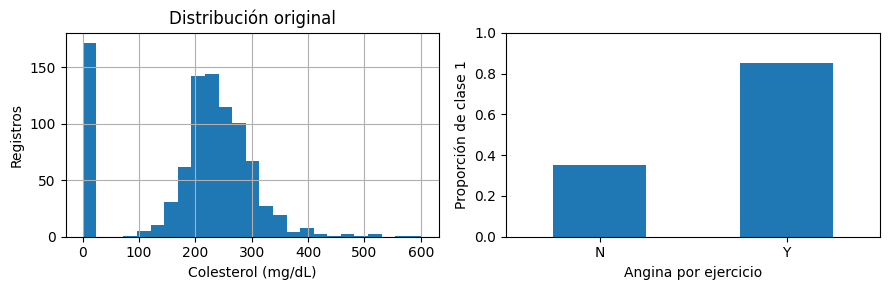

In [ ]:
perfil = pd.DataFrame({"tipo": original.dtypes.astype(str), "nulos": original.isna().sum(),
                       "distintos": original.nunique()})
display(perfil)
y = original[objetivo]
display(y.value_counts().sort_index().rename("registros").to_frame().assign(
    porcentaje=lambda t: (100 * t.registros / len(y)).round(2)))
print("Duplicados exactos:", original.duplicated().sum())
print("Ceros por variable:", original[["Cholesterol", "RestingBP"]].eq(0).sum().to_dict())
display(pd.crosstab(original.Cholesterol.eq(0).rename("Colesterol igual a cero"), y))
display(original[num].describe().T.round(2))
fig, ax = plt.subplots(1, 2, figsize=(9, 3))
original.Cholesterol.hist(ax=ax[0], bins=25)
ax[0].set(xlabel="Colesterol (mg/dL)", ylabel="Registros", title="Distribución original")
pd.crosstab(original.ExerciseAngina, y, normalize="index")[1].plot.bar(ax=ax[1], rot=0)
ax[1].set(xlabel="Angina por ejercicio", ylabel="Proporción de clase 1", ylim=(0,1))
plt.tight_layout()
plt.show()

## 3. Limpieza y selección
Se conservaron los 918 registros. Hay **172 ceros en colesterol y uno en presión**. De los 172 primeros, 152 tienen etiqueta positiva: eliminarlos alteraría la composición de la muestra. Se marcan como ausentes solo en esas dos variables; el archivo no indica la causa. Se añade `Cholesterol_missing` para distinguir una medición disponible de una imputada. El indicador podría reflejar cómo se recogieron los datos.

El criterio intercuartílico identifica extremos, pero no demuestra error de medición. Se conservan y se comprueba que no existan filas idénticas en las predictoras. La misma función de limpieza se reutilizará al recibir un caso nuevo.

El conjunto presenta 508 positivos y 410 negativos. Entre los registros con angina por ejercicio se observa una mayor proporción de enfermedad; esta asociación descriptiva no demuestra causalidad. Por eso evaluamos la predicción conjunta de las variables y no usamos una asociación aislada como regla de decisión.

---



In [ ]:
def preparar_entradas(datos):
    if set(datos.columns) != set(num + cat) or not datos.columns.is_unique:
        raise ValueError("Se requieren exactamente las 11 características originales.")
    x = datos[num + cat].copy()
    for col in num + ["FastingBS"]:
        x[col] = pd.to_numeric(x[col], errors="raise")
        if np.isinf(x[col]).any():
            raise ValueError(f"Valor infinito en {col}")
    permitidas = {"Sex": ["F","M"], "ChestPainType": ["TA","ATA","NAP","ASY"],
                  "FastingBS": [0,1], "RestingECG": ["Normal","ST","LVH"],
                  "ExerciseAngina": ["N","Y"], "ST_Slope": ["Up","Flat","Down"]}
    for col, valores in permitidas.items():
        if not x[col].isin(valores).all():
            raise ValueError(f"Categoría ausente o no documentada en {col}: revisar la entrada.")
    if x[["Age","MaxHR"]].le(0).any().any() or x[["Cholesterol","RestingBP"]].lt(0).any().any():
        raise ValueError("Medición fuera de las reglas de consistencia.")
    x[["Cholesterol","RestingBP"]] = x[["Cholesterol","RestingBP"]].replace(0, np.nan)
    x["Cholesterol_missing"] = x.Cholesterol.isna().astype(int)
    return x

X = preparar_entradas(original.drop(columns=objetivo))
assert not X.duplicated().any()
q1, q3 = X[num].quantile(.25), X[num].quantile(.75)
extremos = X[num].lt(q1 - 1.5*(q3-q1)) | X[num].gt(q3 + 1.5*(q3-q1))
display(pd.DataFrame({"faltantes a imputar": X[num].isna().sum(),
                      "extremos IQR conservados": extremos.sum()}))

,faltantes a imputar,extremos IQR conservados
Age,0,0
RestingBP,1,27
Cholesterol,172,23
MaxHR,0,2
Oldpeak,0,16


### 3.1. Partición y transformación
Se recupera la partición estratificada 80/20 de la fase 3, semilla 42. Se imputan las numéricas con la mediana, menos sensible a extremos que la media, y se codifican las categorías mediante One-Hot. Se estandarizan las numéricas para logística y KNN; el bosque no necesita escalado. El indicador pasa sin transformar.

La validación recibe las columnas **anteriores al ajuste estadístico**. Cada pipeline aprende medianas, categorías y escalas dentro de cada pliegue; prueba nunca participa en ese ajuste.

In [ ]:
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV, cross_validate
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

SEED = 42
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=.2, stratify=y, random_state=SEED)
assert X_train.index.intersection(X_test.index).empty
assert X_train.index.equals(y_train.index) and X_test.index.equals(y_test.index)
display(pd.crosstab(pd.Series(np.where(y.index.isin(y_train.index), "Entrenamiento", "Prueba"),
                              index=y.index, name="Partición"), y))
def pipeline(modelo, escalar):
    pasos = [("mediana", SimpleImputer(strategy="median"))]
    if escalar:
        pasos.append(("escala", StandardScaler()))
    prep = ColumnTransformer([("num", Pipeline(pasos), num),
                              ("cat", OneHotEncoder(handle_unknown="ignore"), cat),
                              ("indicador", "passthrough", ["Cholesterol_missing"])])
    return Pipeline([("prep", prep), ("model", modelo)])

HeartDisease,0,1
Partición,,
Entrenamiento,328,406
Prueba,82,102


## 4. Modelamiento y validación
**Logística** ofrece una referencia lineal regularizada; **KNN** examina semejanza entre registros; **Random Forest** permite interacciones y relaciones no lineales. Se reproduce el diseño del notebook de fase 4 entregado: **28 configuraciones × 5 pliegues = 140 ajustes de búsqueda**, además del reajuste por familia. El indicador se mantiene en las tres familias; esta búsqueda no mide su contribución aislada.

Se comparan los mismos pliegues estratificados y se selecciona el mayor F1 medio de clase 1. La referencia mayoritaria permite detectar la limitación del recall por sí solo: predecir siempre la clase positiva da recall 1 sin distinguir pacientes.

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier

candidatos = {
    "Logística": (pipeline(LogisticRegression(max_iter=1000, random_state=SEED), True),
                  {"model__C":[.01,.1,1,10], "model__class_weight":[None,"balanced"]}),
    "KNN": (pipeline(KNeighborsClassifier(), True),
            {"model__n_neighbors":[3,5,9,15], "model__weights":["uniform","distance"]}),
    "Random Forest": (pipeline(RandomForestClassifier(random_state=SEED), False),
                      {"model__n_estimators":[100,200], "model__max_depth":[5,10,None],
                       "model__min_samples_leaf":[1,5]})}
cv = list(StratifiedKFold(5, shuffle=True, random_state=SEED).split(X_train, y_train))
metricas = {"F1":"f1", "Recall":"recall", "Precisión":"precision",
            "Exactitud":"accuracy", "AUC":"roc_auc"}
busquedas, filas = {}, []
base = cross_validate(DummyClassifier(strategy="most_frequent"), X_train, y_train,
                      cv=cv, scoring=metricas)
filas.append({"Modelo":"Mayoritaria", **{m:base["test_"+m].mean() for m in metricas}})
for nombre, (estimador, rejilla) in candidatos.items():
    g = GridSearchCV(estimador, rejilla, cv=cv, scoring=metricas, refit="F1",
                     return_train_score=True, error_score="raise", n_jobs=1)
    g.fit(X_train, y_train)
    busquedas[nombre] = g
    i = g.best_index_
    filas.append({"Modelo":nombre, **{m:g.cv_results_["mean_test_"+m][i] for m in metricas},
                  "DE F1":g.cv_results_["std_test_F1"][i], "Parámetros":g.best_params_})
tabla = pd.DataFrame(filas).set_index("Modelo")
display(tabla.round(4))
ganador = max(busquedas, key=lambda nombre: busquedas[nombre].best_score_)
modelo_final = busquedas[ganador].best_estimator_
print("Seleccionado por validación:", ganador, busquedas[ganador].best_params_)

,F1,Recall,Precisión,Exactitud,AUC,DE F1,Parámetros
Modelo,,,,,,,
Mayoritaria,0.7123,1.0000,0.5531,0.5531,0.5000,NaN,NaN
Logística,0.8751,0.8917,0.8604,0.8583,0.9256,0.0258,"{'model__C': 0.1, 'model__class_weight': None}"
KNN,0.8720,0.8793,0.8650,0.8570,0.9162,0.0268,"{'model__n_neighbors': 15, 'model__weights': '..."
Random Forest,0.8863,0.9163,0.8589,0.8692,0.9332,0.0295,"{'model__max_depth': 5, 'model__min_samples_le..."


Seleccionado por validación: Random Forest {'model__max_depth': 5, 'model__min_samples_leaf': 5, 'model__n_estimators': 200}


### 4.1. Efecto de la complejidad
Cada panel varía **un solo hiperparámetro** y mantiene los demás en la mejor configuración de su familia. La separación entre las curvas de entrenamiento y validación ayuda a detectar qué mejoras de ajuste se trasladan a observaciones reservadas.

En la ejecución de referencia el bosque obtuvo F1 medio de **0,8863** frente a **0,8751** de logística, **0,8720** de KNN y **0,7123** de la referencia. El bosque seleccionado usa 200 árboles, profundidad máxima 5 y un mínimo de 5 registros por hoja. Las diferencias pequeñas entre familias no prueban superioridad estadística.

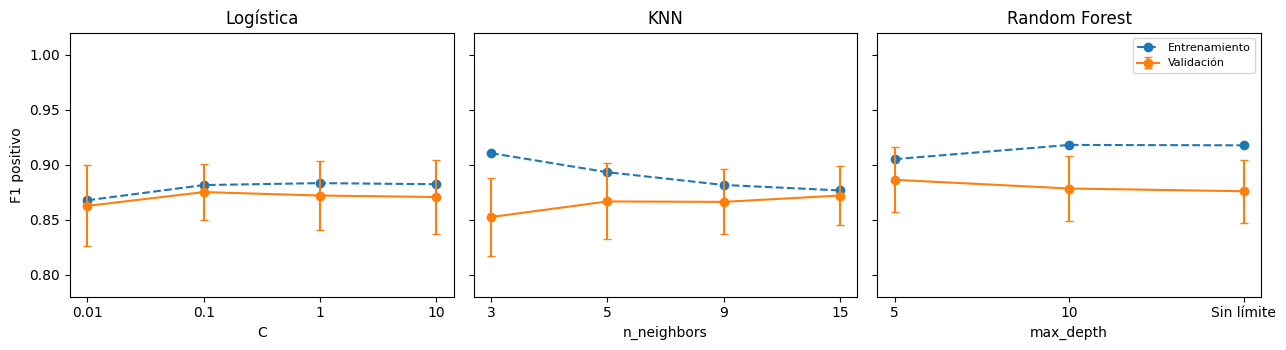

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6), sharey=True)
for ax, (nombre, parametro) in zip(axes, [("Logística","model__C"),
        ("KNN","model__n_neighbors"),("Random Forest","model__max_depth")]):
    g = busquedas[nombre]
    r = pd.DataFrame(g.cv_results_)
    fijos = {k:v for k,v in g.best_params_.items() if k != parametro}
    r = r[r.params.map(lambda p: all(p[k] == v for k,v in fijos.items()))]
    etiquetas = [str(p[parametro]) if p[parametro] is not None else "Sin límite" for p in r.params]
    ax.plot(etiquetas, r.mean_train_F1, "o--", label="Entrenamiento")
    ax.errorbar(etiquetas, r.mean_test_F1, yerr=r.std_test_F1, fmt="o-", capsize=3, label="Validación")
    ax.set(title=nombre, xlabel=parametro.replace("model__", ""), ylim=(.78,1.02))
axes[0].set_ylabel("F1 positivo")
axes[-1].legend(fontsize=8)
plt.tight_layout()
plt.show()

### 4.2. Evaluación sobre prueba
Se evalúa el pipeline seleccionado y reajustado en 734 registros sobre los **184 reservados**, sin cambiar configuración ni umbral. Se comparan el F1 de validación y el de prueba. Para ROC-AUC se usan probabilidades; para los errores se usan las clases predichas. La especificidad complementa el recall al describir qué fracción de los negativos reales se reconoció.

,Validación,Prueba
F1,0.8863,0.9100
Recall,0.9163,0.9412
Precisión,0.8589,0.8807
Exactitud,0.8692,0.8967
AUC,0.9332,0.9342


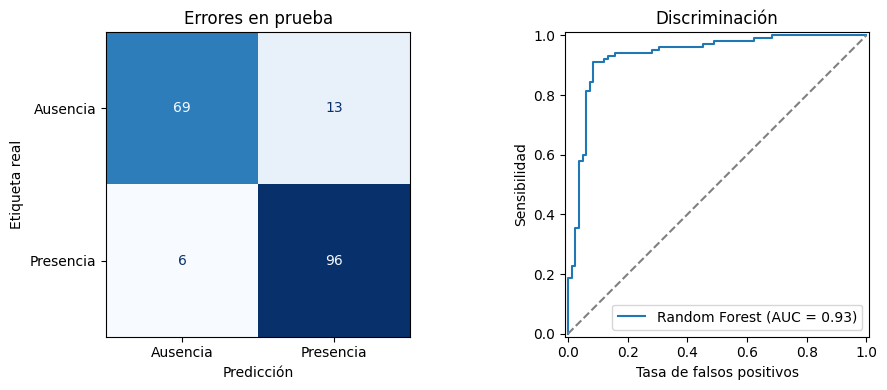

**Interpretación:** se detectaron 96 de 102 positivos; quedaron 6 falsos negativos. Hubo 13 falsas alarmas entre 82 negativos (especificidad 84.1%). El AUC describe ordenamiento, no calibración.

In [ ]:
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix, ConfusionMatrixDisplay, RocCurveDisplay)
pred = modelo_final.predict(X_test)
prob = modelo_final.predict_proba(X_test)[:, list(modelo_final.classes_).index(1)]
cm = confusion_matrix(y_test, pred, labels=[0,1])
vn, fp, fn, vp = cm.ravel()
prueba = pd.Series({"F1": f1_score(y_test,pred), "Recall": recall_score(y_test,pred),
                    "Precisión": precision_score(y_test,pred), "Exactitud": accuracy_score(y_test,pred),
                    "AUC": roc_auc_score(y_test,prob)}, name="Prueba")
display(pd.concat([tabla.loc[ganador, list(metricas)].astype(float).rename("Validación"), prueba], axis=1).round(4))
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
ConfusionMatrixDisplay(cm, display_labels=["Ausencia","Presencia"]).plot(ax=ax[0], cmap="Blues", colorbar=False)
ax[0].set(xlabel="Predicción", ylabel="Etiqueta real", title="Errores en prueba")
RocCurveDisplay.from_predictions(y_test, prob, ax=ax[1], name=ganador)
ax[1].plot([0,1],[0,1],"--",color="gray")
ax[1].set(xlabel="Tasa de falsos positivos", ylabel="Sensibilidad", title="Discriminación")
plt.tight_layout()
plt.show()
display(Markdown(f"**Interpretación:** se detectaron {vp} de {vp+fn} positivos; quedaron "
                 f"{fn} falsos negativos. Hubo {fp} falsas alarmas entre {vn+fp} negativos "
                 f"(especificidad {vn/(vn+fp):.1%}). El AUC describe ordenamiento, no calibración."))

### 4.3. Aplicación y conclusión
Se utiliza el registro hipotético de la cuarta entrega. La entrada contiene las mismas once variables originales: el indicador lo construye la función de limpieza. El ejemplo demuestra el flujo técnico; no tiene etiqueta real y no permite estimar desempeño externo.

**Límites y siguiente decisión:** conservar el prototipo académico. Antes de considerar su utilización en otra institución se requieren registros externos etiquetados, evaluación por subgrupos (la muestra contiene más hombres que mujeres) y calibración si se interpretarán probabilidades. La asociación del indicador de colesterol podría reflejar diferencias de procedencia. La prueba ya se exploró descriptivamente en fases anteriores y no debe reutilizarse para elegir ajustes.

**Créditos:** equipo del proyecto aplicado y material docente MLDS, Universidad Nacional de Colombia. [Fuente de los datos](https://www.kaggle.com/datasets/fedesoriano/heart-failure-prediction).

**Impacto frente a la referencia, en los 184 registros reservados.** Predecir siempre la clase positiva habría marcado los 184 registros: 102 aciertos positivos y 82 falsas alarmas. El bosque marcó **109**: 96 aciertos positivos y 13 falsas alarmas. Si cada positivo activara una revisión, serían **75 revisiones menos**, a cambio de **6 positivos omitidos**. Esta comparación cuantifica el compromiso que debe valorar el beneficiario; no demuestra ahorro real, seguridad clínica ni mejora en pacientes. La reproducción de la prueba ya utilizada en fase 4 no constituye una validación independiente nueva.

In [ ]:
caso = pd.DataFrame([{"Age":55,"Sex":"M","ChestPainType":"ASY","RestingBP":140,
                      "Cholesterol":240,"FastingBS":0,"RestingECG":"Normal","MaxHR":130,
                      "ExerciseAngina":"Y","Oldpeak":1.5,"ST_Slope":"Flat"}])
entrada = preparar_entradas(caso)
assert not X.eq(entrada.iloc[0]).all(axis=1).any(), "El ejemplo coincide con un registro original."
clase = modelo_final.predict(entrada)[0]
puntaje = modelo_final.predict_proba(entrada)[0, list(modelo_final.classes_).index(1)]
display(pd.DataFrame({"Ejemplo":["Sintético"], "Clase predicha":[clase],
                      "Probabilidad estimada (sin calibrar)":[round(puntaje,4)]}))
display(Markdown(f"**Conclusión:** {ganador} alcanzó F1={prueba['F1']:.4f} en prueba, con "
                 f"{fn} casos positivos omitidos y {fp} falsas alarmas. El resultado respalda "
                 "continuar la investigación; no valida un diagnóstico individual. **Fin del proyecto.**"))

,Ejemplo,Clase predicha,Probabilidad estimada (sin calibrar)
0,Sintético,1,0.9299


**Conclusión:** Random Forest alcanzó F1=0.9100 en prueba, con 6 casos positivos omitidos y 13 falsas alarmas. El resultado respalda continuar la investigación; no valida un diagnóstico individual. **Fin del proyecto.**